In [1]:
# Imports and configuration
import warnings
warnings.filterwarnings('ignore')
import re, time, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf

from dtaidistance import dtw
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import squareform
from sklearn.metrics import (silhouette_score, calinski_harabasz_score,
                             davies_bouldin_score, adjusted_rand_score)
from statsmodels.tsa.stattools import coint
from statsmodels.stats.multitest import multipletests
import statsmodels.api as sm
from pykalman import KalmanFilter

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.4f}'.format)
plt.style.use('seaborn-v0_8-whitegrid')
np.random.seed(42)

# Data
DATA_START   = '2000-01-01'   # one buffer year so the 52-week rolling Sharpe covers all of Train
END_DATE     = '2026-01-01'
SNAPSHOT     = '2001-01-01'   # constituent snapshot date
BENCHMARK    = '^SP500TR'          # auto-adjusted, so dividends are included
RF_TICKER    = '^IRX'         # 13-week T-bill yield, annualized percent
FALLBACK_RF  = 0.0            # used only if ^IRX fails to download

# Periods
TRAIN_START, TRAIN_END = '2001-01-01', '2008-12-31'   # 8 years
VAL_START,   VAL_END   = '2009-01-01', '2016-12-31'   # 8 years
TEST_START,  TEST_END  = '2017-01-01', '2025-12-31'   # 9 years

# Clustering
ROLLING_WINDOW = 52
K_VALUES       = [2, 4, 7]
K_COINT        = 7      # pair formation uses k=7 clusters to keep the candidate pool tractable
N_CORES        = 10     # only used by the multiprocess fallback for OCP

# Strategy parameters 
ZSCORE_WINDOW  = 52
VOL_WINDOW     = 26
VOL_THRESHOLD  = 1.5
HIGH_VOL_ENTRY = 2.25
LOW_VOL_ENTRY  = 1.25
STANDARD_ENTRY = 1.75
EXIT_THRESHOLD = 0.5
STOP_LOSS      = 3.25

CANDIDATE_MULTIPLIERS = [0.60, 0.75, 0.85, 1.00, 1.15, 1.25]
ACTIVITY_FLOOR        = 0.50
COST_LEVELS_BPS       = [0, 5, 10, 20]

N_BOOT, BLOCK_SIZE, BOOT_SEED = 5000, 8, 42

# calendar version (robustness). Everything outside the windows is bull.
BEAR_WINDOWS_PRIMARY = [('2018-09-20', '2018-12-24'),
                        ('2020-02-19', '2020-03-23'),
                        ('2022-01-03', '2022-10-12')]
BEAR_WINDOWS_ALT     = [('2018-10-01', '2018-12-31'),
                        ('2020-02-19', '2020-03-23'),
                        ('2022-01-03', '2022-10-12')]

METHODS = ['DTW', 'OCP', 'CORR']
LABELS  = {'DTW': 'DTW-Clustering', 'OCP': 'OCP-Clustering',
           'CORR': 'Correlation Pairs', 'Naive': 'Naive Buy-and-Hold'}
COLORS  = {'DTW': '#1f77b4', 'OCP': '#ff7f0e', 'CORR': '#2ca02c', 'Naive': '#7f7f7f'}
TAG     = 'sp500_25y'

def n_years(a, b):
    return round((pd.Timestamp(b) - pd.Timestamp(a)).days / 365.25)

print('DTW vs OCP vs Correlation Pairs vs Naive, S&P 500 25-Year Framework')
print(f'Train: {TRAIN_START} to {TRAIN_END} ({n_years(TRAIN_START, TRAIN_END)} years)')
print(f'Val:   {VAL_START} to {VAL_END} ({n_years(VAL_START, VAL_END)} years)')
print(f'Test:  {TEST_START} to {TEST_END} ({n_years(TEST_START, TEST_END)} years)')

DTW vs OCP vs Correlation Pairs vs Naive, S&P 500 25-Year Framework
Train: 2001-01-01 to 2008-12-31 (8 years)
Val:   2009-01-01 to 2016-12-31 (8 years)
Test:  2017-01-01 to 2025-12-31 (9 years)


In [2]:
# S&P 500 constituents as of the snapshot date (point-in-time membership list)
hist_url = ('https://raw.githubusercontent.com/fja05680/sp500/master/'
            'S%26P%20500%20Historical%20Components%20%26%20Changes.csv')
hist = pd.read_csv(hist_url)
hist['date'] = pd.to_datetime(hist['date'])

target_date  = pd.Timestamp(SNAPSHOT)
snapshot_row = hist[hist['date'] <= target_date].sort_values('date').iloc[-1]
raw_tickers  = sorted(t.strip() for t in snapshot_row['tickers'].split(','))

suffix_pattern = re.compile(r'-\d{6}$')   # dataset's own delisting-date suffix
universe = sorted(set(suffix_pattern.sub('', t).replace('.', '-') for t in raw_tickers))

n_suffixed = sum(1 for t in raw_tickers if suffix_pattern.search(t))
print(f'Using snapshot date: {snapshot_row["date"].date()}')
print(f'Tickers with a delisting-date suffix in the source data: {n_suffixed}')
print(f'S&P 500 constituents as of {target_date.date()}: {len(universe)} stocks')

Using snapshot date: 2000-12-29
Tickers with a delisting-date suffix in the source data: 204
S&P 500 constituents as of 2001-01-01: 492 stocks


In [3]:
# Prices: daily download, resampled to true Wednesday closes
def to_close_frame(raw):
    close = raw['Close'] if isinstance(raw.columns, pd.MultiIndex) else raw[['Close']]
    return close if isinstance(close, pd.DataFrame) else close.to_frame()

print(f'Downloading daily prices for {len(universe)} stocks...')
raw = yf.download(universe, start=DATA_START, end=END_DATE, interval='1d',
                  auto_adjust=True, progress=True, threads=True)
daily = to_close_frame(raw)
price_data = daily.resample('W-WED').last().dropna(how='all')

before_drop = len(universe)
price_data  = price_data.ffill().dropna(axis=1)   # complete history required

TAIL_WINDOW = 10
flatlined = [t for t in price_data.columns
             if price_data[t].iloc[-TAIL_WINDOW:].nunique() == 1]
price_data = price_data.drop(columns=flatlined)

dropped_tickers = sorted(set(universe) - set(price_data.columns))
print(f'\nPrice data shape: {price_data.shape}')
print(f'Date range: {price_data.index[0].date()} to {price_data.index[-1].date()}')
print(f'Retained: {price_data.shape[1]} of {before_drop} (dropped {len(dropped_tickers)}, '
      f'of which {len(flatlined)} flatlined)')
print(f'Dropped tickers: {dropped_tickers}')

# Benchmark: S&P 500 Total Return index (dividends reinvested, no fees)
bench_raw = to_close_frame(yf.download(BENCHMARK, start=DATA_START, end=END_DATE,
                                       interval='1d', auto_adjust=True, progress=False))
bench_weekly = bench_raw.iloc[:, 0].resample('W-WED').last().reindex(price_data.index)
n_missing = int(bench_weekly.isna().sum())
print(f'\nBenchmark {BENCHMARK}: {n_missing} missing weeks before filling (should be 0)')
bench_price = bench_weekly.ffill()

try:
    irx_raw = to_close_frame(yf.download(RF_TICKER, start=DATA_START, end=END_DATE,
                                         interval='1d', auto_adjust=False, progress=False))
    irx = irx_raw.iloc[:, 0].resample('W-WED').last().reindex(price_data.index).ffill().bfill()
    rf_weekly = np.log1p(irx / 100) / 52       # weekly log risk-free rate
    print(f'T-bill loaded: mean annual yield over sample {irx.mean():.2f}%')
except Exception as e:
    rf_weekly = pd.Series(FALLBACK_RF / 52, index=price_data.index)
    print(f'^IRX download failed ({e}); using constant rf={FALLBACK_RF}')

price_data.to_csv(f'price_data_{TAG}.csv')

$JP: possibly delisted; no timezone found
HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: AL"}}}
$LEG: possibly delisted; no price data found  (1d 2000-01-01 -> 2026-01-01) (Yahoo error = "Data doesn't exist for startDate = 946702800, endDate = 1767243600")
[                       0%                       ]  2 of 492 completed$GDT: possibly delisted; no price data found  (1d 2000-01-01 -> 2026-01-01) (Yahoo error = "Data doesn't exist for startDate = 946702800, endDate = 1767243600")
[                       1%                       ]  3 of 492 completedHTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: OAT"}}}
$AL: possibly delisted; no timezone found
$OAT: possibly delisted; no timezone found       ]  4 of 492 completed
$JCP: possibly delisted; no timezone found       ]  14 of 492 completed
$RDC: possibly delisted; no timezone found       ]  19 of 49


Price data shape: (1357, 236)
Date range: 2000-01-05 to 2025-12-31
Retained: 236 of 492 (dropped 256, of which 0 flatlined)
Dropped tickers: ['AABA', 'AAMRQ', 'ABI', 'ABKFQ', 'ABS', 'ABX', 'ACV', 'ADCT', 'AET', 'AGC', 'AGN', 'AL', 'ALTR', 'AM', 'ANDW', 'APC', 'APCC', 'ARNC', 'ASO', 'AT', 'AV', 'AVP', 'AW', 'AYE', 'AZA-A', 'BBBY', 'BBT', 'BCR', 'BDK', 'BEAM', 'BGEN', 'BGG', 'BHGE', 'BIG', 'BK', 'BLL', 'BLS', 'BMC', 'BMET', 'BMS', 'BNI', 'BOL', 'BR', 'BRCM', 'BSC', 'BUD', 'BVSN', 'CA', 'CBE', 'CBS', 'CCE', 'CCTYQ', 'CEG', 'CEN', 'CF', 'CFC', 'CGP', 'CHIR', 'CIN', 'CIT-A', 'CMA', 'CMVT', 'CNC', 'CNXT', 'COC-B', 'CPNLQ', 'CPQ', 'CPWR', 'CR', 'CTB', 'CTL', 'CTX', 'CTXS', 'CVG', 'DALRQ', 'DCNAQ', 'DELL', 'DG', 'DJ', 'DOW', 'DPHIQ', 'DYN', 'EC', 'EDS', 'EKDKQ', 'EMC', 'ENRNQ', 'ETS', 'FBF', 'FDC', 'FLR', 'FRX', 'G', 'GAS', 'GDT', 'GDW', 'GLK', 'GP', 'GPS', 'GPU', 'GR', 'GTW', 'GX', 'H', 'HCA', 'HCR', 'HES', 'HET', 'HI', 'HLT', 'HM', 'HNZ', 'HOT', 'HPC', 'HSH', 'INCLF', 'IPG', 'IR', 'JAVA', '

In [21]:
# Data screen (no price re-download): current company name and exchange for every retained ticker
info_rows = []
for t in price_data.columns:
    try:
        inf = yf.Ticker(t).info
        info_rows.append({'ticker': t, 'name': inf.get('longName'),
                          'exchange': inf.get('exchange'), 'type': inf.get('quoteType')})
    except Exception as e:
        info_rows.append({'ticker': t, 'name': None, 'exchange': None, 'type': f'error: {e}'[:40]})
info_df = pd.DataFrame(info_rows)
info_df.to_csv(f'ticker_screen_{TAG}.csv', index=False)

In [22]:
# Show the full screen, then the rows worth a closer look
print(info_df.to_string(index=False))

MAJOR = ['NYQ', 'NMS', 'NGM', 'NCM', 'ASE', 'PCX', 'BTS']   # NYSE, Nasdaq tiers, NYSE American/Arca, Cboe
flag = info_df[~info_df['exchange'].isin(MAJOR) | (info_df['type'] != 'EQUITY')]
print(f'\nFlagged for review ({len(flag)}):')
print(flag.to_string(index=False))

ticker                                         name exchange   type
     A                   Agilent Technologies, Inc.      NYQ EQUITY
  AAPL                                   Apple Inc.      NMS EQUITY
   ABT                          Abbott Laboratories      NYQ EQUITY
  ADBE                                   Adobe Inc.      NMS EQUITY
   ADI                         Analog Devices, Inc.      NMS EQUITY
   ADM               Archer-Daniels-Midland Company      NYQ EQUITY
   ADP              Automatic Data Processing, Inc.      NMS EQUITY
  ADSK                               Autodesk, Inc.      NMS EQUITY
   AEE                           Ameren Corporation      NYQ EQUITY
   AEP        American Electric Power Company, Inc.      NMS EQUITY
   AES                          The AES Corporation      NYQ EQUITY
   AFL                           Aflac Incorporated      NYQ EQUITY
   AIG           American International Group, Inc.      NYQ EQUITY
   ALL                     The Allstate Corporat

In [23]:
EXCLUDE = ['FNMA', 'FMCC', 'EP', 'CCU']   # add 'CB' and/or 'T' depending on the check above
price_data = price_data.drop(columns=[t for t in EXCLUDE if t in price_data.columns])
print(f'Excluded {EXCLUDE}; universe now {price_data.shape[1]} stocks')

Excluded ['FNMA', 'FMCC', 'EP', 'CCU']; universe now 232 stocks


In [25]:
# 52-week rolling Sharpe ratio in excess of the T-bill
log_returns  = np.log(price_data / price_data.shift(1))
excess_lr    = log_returns.sub(rf_weekly, axis=0)
rolling_mean = excess_lr.rolling(ROLLING_WINDOW).mean()
rolling_std  = log_returns.rolling(ROLLING_WINDOW).std()
sharpe_data  = (rolling_mean / rolling_std * np.sqrt(52)).dropna(how='all')

train_sharpe_data = sharpe_data.loc[TRAIN_START:TRAIN_END]
bad_cols = train_sharpe_data.columns[
    train_sharpe_data.isna().any() | np.isinf(train_sharpe_data).any()].tolist()
if bad_cols:
    train_sharpe_data = train_sharpe_data.drop(columns=bad_cols)
    print(f'Dropped {bad_cols} (NaN or inf rolling Sharpe in Train)')

tickers = train_sharpe_data.columns.tolist()
n = len(tickers)
print(f'Clustering universe: {n} stocks, {n*(n-1)//2:,} pairs, '
      f'{len(train_sharpe_data)} Train weeks')

Clustering universe: 232 stocks, 26,796 pairs, 418 Train weeks


In [26]:
# DTW distance matrix (Train only), absolute-difference cost to match OCP and Stübinger (2019)
from numba import njit, prange

@njit(cache=True)
def _dtw_abs(x, y):
    n, m = len(x), len(y)
    prev = np.full(m, np.inf)
    for i in range(n):
        cur = np.full(m, np.inf)
        for j in range(m):                      # DTW: any j (no causality constraint)
            if i == 0 and j == 0:
                cur[0] = abs(x[0] - y[0])
                continue
            best = np.inf
            if i > 0 and prev[j] < best:
                best = prev[j]
            if j > 0 and cur[j - 1] < best:
                best = cur[j - 1]
            if i > 0 and j > 0 and prev[j - 1] < best:
                best = prev[j - 1]
            cur[j] = abs(x[i] - y[j]) + best
        prev = cur
    return prev[m - 1]

@njit(parallel=True, cache=True)
def _dtw_matrix(X):
    n = X.shape[1]
    D = np.zeros((n, n))
    for i in prange(n):
        for j in range(i + 1, n):
            d = _dtw_abs(X[:, i], X[:, j])
            D[i, j] = d
            D[j, i] = d
    return D

X = train_sharpe_data[tickers].values.astype(np.float64)
t0 = time.time()
dtw_distance_matrix = _dtw_matrix(X)
print(f'DTW distance matrix computed in {time.time()-t0:.1f} seconds, shape {dtw_distance_matrix.shape}')
np.save(f'dtw_distance_matrix_{TAG}_train.npy', dtw_distance_matrix)

DTW distance matrix computed in 7.4 seconds, shape (232, 232)


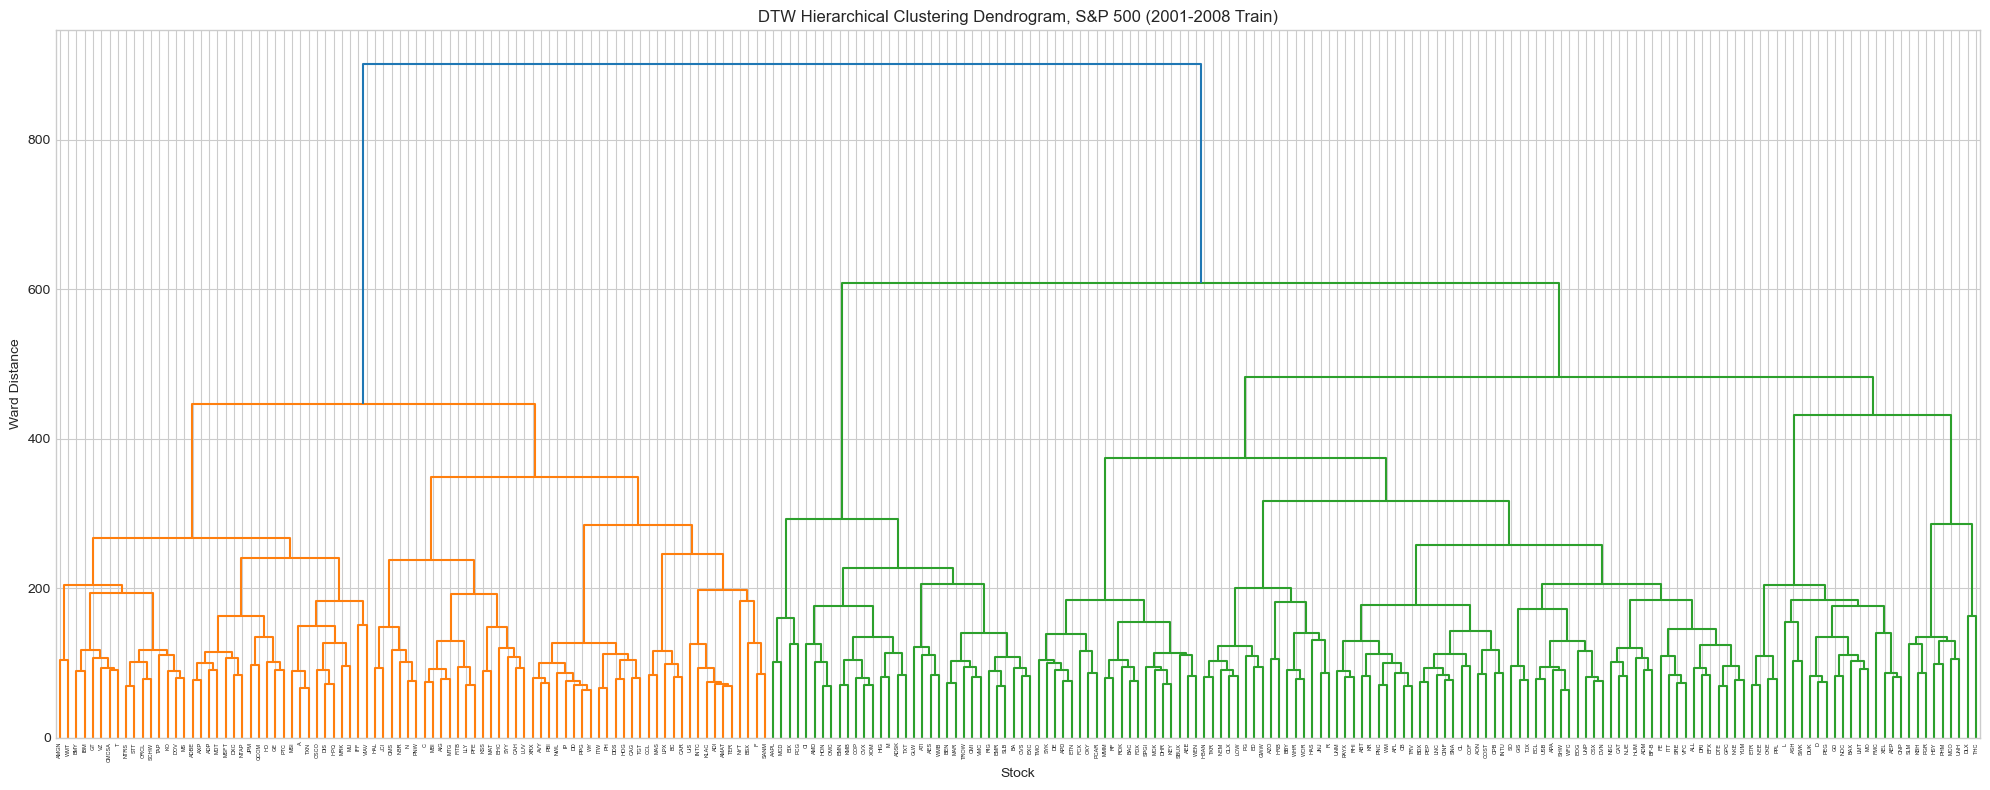

DTW Cluster Validation Summary:
   k                        sizes  silhouette  calinski_harabasz  \
0  2                    [86, 146]      0.1277            26.5592   
1  4             [86, 32, 86, 28]      0.0777            14.7371   
2  7  [38, 48, 32, 20, 66, 19, 9]      0.0614            11.8962   

   davies_bouldin  
0          2.7596  
1          3.4701  
2          3.1062  
Preferred k by index: {'silhouette': np.int64(2), 'calinski_harabasz': np.int64(2), 'davies_bouldin': np.int64(2)}


In [27]:
def cluster_and_validate(dist, name):
    link = linkage(squareform(dist, checks=False), method='ward')
    clusters, cvi = {}, []
    for k in K_VALUES:
        clusters[k] = fcluster(link, t=k, criterion='maxclust')
        sizes = pd.Series(clusters[k]).value_counts().sort_index().tolist()
        sil = silhouette_score(dist, clusters[k], metric='precomputed')
        ch  = calinski_harabasz_score(train_sharpe_data.T, clusters[k])
        db  = davies_bouldin_score(train_sharpe_data.T, clusters[k])
        cvi.append({'k': k, 'sizes': sizes, 'silhouette': sil,
                    'calinski_harabasz': ch, 'davies_bouldin': db})

    fig, ax = plt.subplots(figsize=(20, 8))
    dendrogram(link, labels=tickers, leaf_rotation=90, leaf_font_size=4, ax=ax)
    ax.set_title(f'{name} Hierarchical Clustering Dendrogram, S&P 500 '
                 f'({TRAIN_START[:4]}-{TRAIN_END[:4]} Train)')
    ax.set_xlabel('Stock'); ax.set_ylabel('Ward Distance')
    plt.tight_layout()
    plt.savefig(f'{name.lower()}_dendrogram_{TAG}.png', dpi=150, bbox_inches='tight')
    plt.show()

    df = pd.DataFrame({'ticker': tickers})
    for k in K_VALUES:
        df[f'cluster_k{k}'] = clusters[k]
    df.to_csv(f'{name.lower()}_cluster_assignments_{TAG}.csv', index=False)

    cvi_df = pd.DataFrame(cvi)
    print(f'{name} Cluster Validation Summary:')
    print(cvi_df)
    best = {'silhouette': cvi_df.loc[cvi_df['silhouette'].idxmax(), 'k'],
            'calinski_harabasz': cvi_df.loc[cvi_df['calinski_harabasz'].idxmax(), 'k'],
            'davies_bouldin': cvi_df.loc[cvi_df['davies_bouldin'].idxmin(), 'k']}
    print(f'Preferred k by index: {best}')
    return clusters, df, cvi_df

dtw_clusters, dtw_clusters_df, dtw_cvi_df = cluster_and_validate(dtw_distance_matrix, 'DTW')   

In [28]:
print(train_sharpe_data.shape)                                   # expect (418, 236)
print(train_sharpe_data.index[0].date(), train_sharpe_data.index[-1].date())   # expect 2001-01-03 to 2008-12-31
print('NaN:', train_sharpe_data.isna().sum().sum(), ' inf:', np.isinf(train_sharpe_data).sum().sum())   # expect 0 and 0
print(train_sharpe_data.stack().describe())                      # values should mostly fall between about -3 and +4

(418, 232)
2001-01-03 2008-12-31
NaN: 0  inf: 0
count   96976.0000
mean        0.2331
std         0.9615
min        -3.1290
25%        -0.4347
50%         0.2275
75%         0.8851
max         4.8208
dtype: float64


In [29]:
# OCP distance matrix (Train only): absolute-difference cost (Stübinger, 2019),
# causality constraint j >= i, computed in both directions, minimum taken
@njit(cache=True)
def _ocp_one_way(x, y):
    n, m = len(x), len(y)
    prev = np.full(m, np.inf)
    for i in range(n):
        cur = np.full(m, np.inf)
        for j in range(i, m):                   # OCP: only j >= i (causality constraint)
            if i == 0 and j == 0:
                cur[0] = abs(x[0] - y[0])
                continue
            best = np.inf
            if i > 0 and prev[j] < best:
                best = prev[j]
            if j > 0 and cur[j - 1] < best:
                best = cur[j - 1]
            if i > 0 and j > 0 and prev[j - 1] < best:
                best = prev[j - 1]
            cur[j] = abs(x[i] - y[j]) + best
        prev = cur
    return prev[m - 1]

@njit(parallel=True, cache=True)
def _ocp_matrix(X):
    n = X.shape[1]
    D = np.zeros((n, n))
    for i in prange(n):
        for j in range(i + 1, n):
            d = min(_ocp_one_way(X[:, i], X[:, j]), _ocp_one_way(X[:, j], X[:, i]))
            D[i, j] = d
            D[j, i] = d
    return D

t0 = time.time()
ocp_matrix = _ocp_matrix(X)
print(f'OCP distance matrix computed in {time.time()-t0:.1f} seconds, shape {ocp_matrix.shape}')
np.save(f'ocp_distance_matrix_{TAG}_train.npy', ocp_matrix)

OCP distance matrix computed in 11.7 seconds, shape (232, 232)


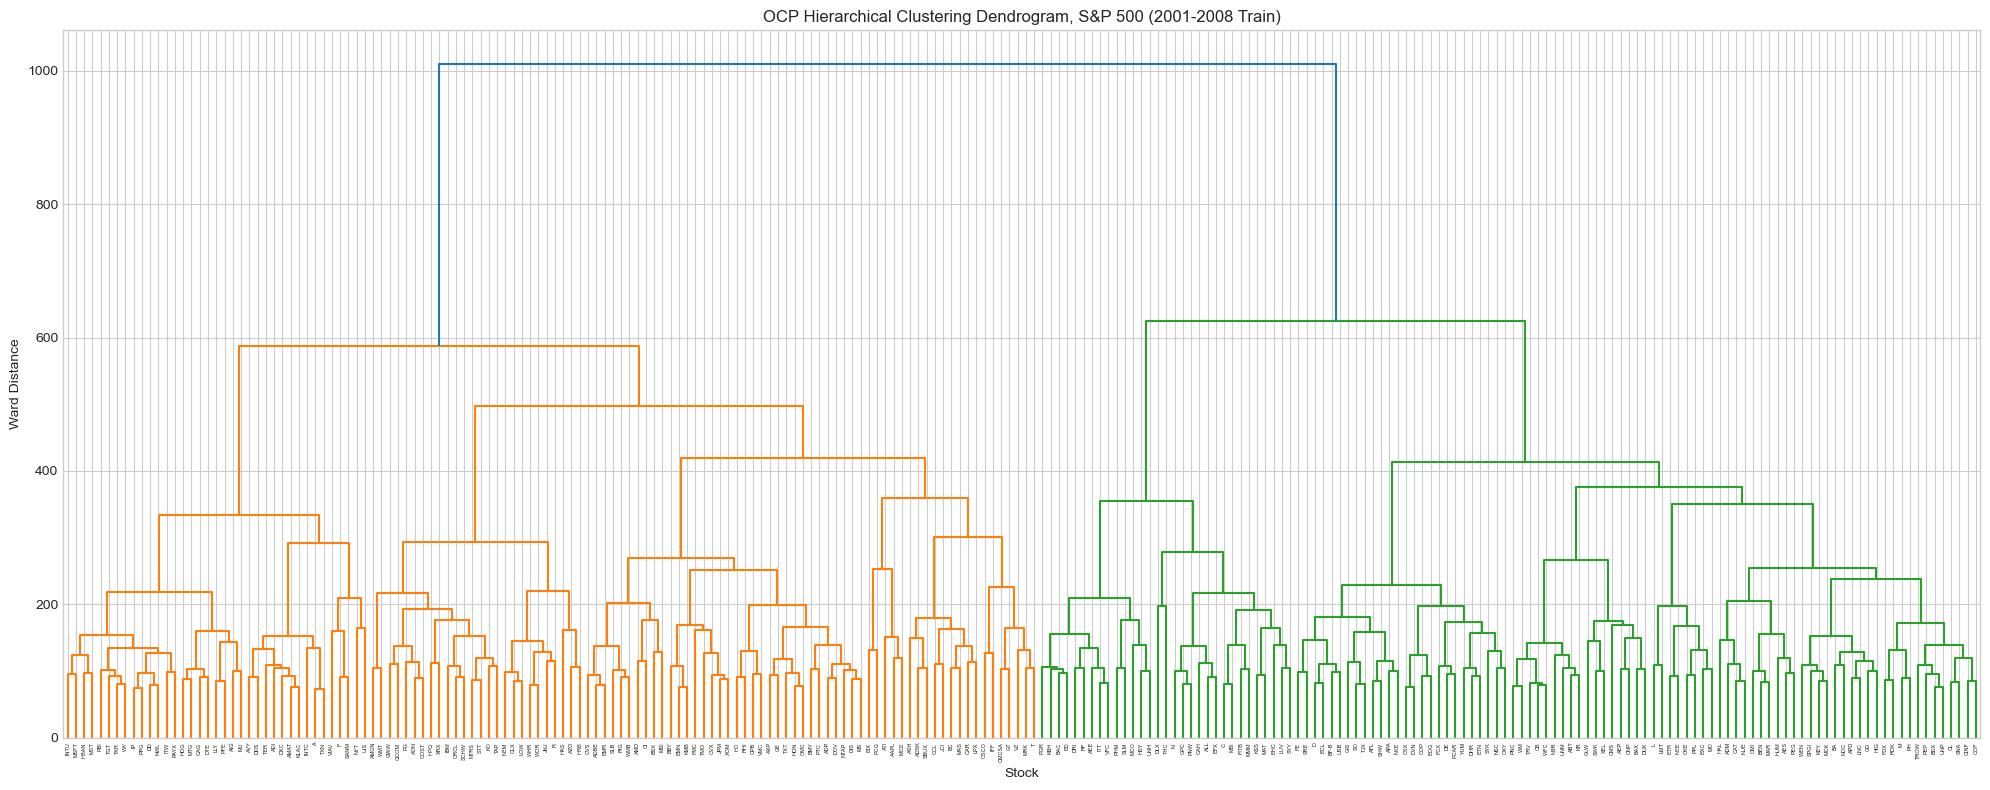

OCP Cluster Validation Summary:
   k                         sizes  silhouette  calinski_harabasz  \
0  2                    [118, 114]      0.1218            16.9669   
1  4              [37, 81, 31, 83]      0.0644            13.3400   
2  7  [37, 26, 34, 21, 31, 26, 57]      0.0475             9.0954   

   davies_bouldin  
0          3.5740  
1          3.4639  
2          3.8395  
Preferred k by index: {'silhouette': np.int64(2), 'calinski_harabasz': np.int64(2), 'davies_bouldin': np.int64(4)}


In [30]:
ocp_clusters, ocp_clusters_df, ocp_cvi_df = cluster_and_validate(ocp_matrix, 'OCP')

   k  ARI_DTW_vs_OCP
0  2          0.2135
1  4          0.1557
2  7          0.1644


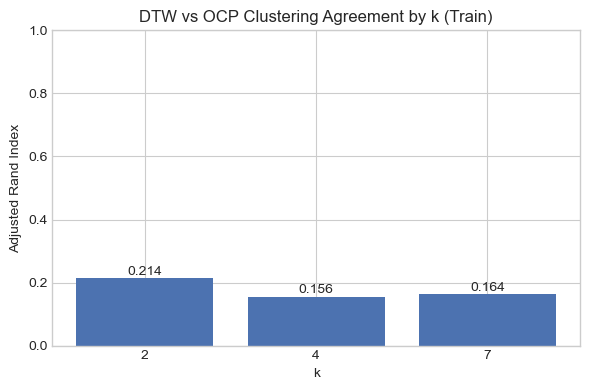

In [31]:
# DTW-OCP clustering agreement (Adjusted Rand Index) at each k
ari_df = pd.DataFrame([{'k': k, 'ARI_DTW_vs_OCP': adjusted_rand_score(dtw_clusters[k], ocp_clusters[k])}
                       for k in K_VALUES])
print(ari_df)

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(ari_df['k'].astype(str), ari_df['ARI_DTW_vs_OCP'], color='#4c72b0')
for i, v in enumerate(ari_df['ARI_DTW_vs_OCP']):
    ax.text(i, v + 0.01, f'{v:.3f}', ha='center')
ax.set_ylim(0, 1); ax.set_xlabel('k'); ax.set_ylabel('Adjusted Rand Index')
ax.set_title('DTW vs OCP Clustering Agreement by k (Train)')
plt.tight_layout()
plt.savefig(f'ari_dtw_ocp_by_k_{TAG}.png', dpi=150, bbox_inches='tight')
plt.show()
ari_df.to_csv(f'ari_dtw_ocp_{TAG}.csv', index=False)

In [32]:
# Do DTW and OCP rank stock similarity the same way? (Spearman correlation of all pair distances)
from scipy.stats import spearmanr

iu = np.triu_indices(len(tickers), k=1)          # every unique pair (upper triangle, no diagonal)
rho = spearmanr(dtw_distance_matrix[iu], ocp_matrix[iu]).correlation
print(f'Spearman correlation between DTW and OCP distances: {rho:.3f} '
      f'({len(iu[0]):,} pairs)')

Spearman correlation between DTW and OCP distances: 0.888 (26,796 pairs)


In [33]:
train_price_data = price_data.loc[TRAIN_START:TRAIN_END]

def test_cointegration_within_clusters(clusters_df, prices, method_name, k_col=f'cluster_k{K_COINT}', alpha=0.05):
    rows = []
    for cid in sorted(clusters_df[k_col].unique()):
        members = clusters_df.loc[clusters_df[k_col] == cid, 'ticker'].tolist()
        for a in range(len(members)):
            for b in range(a + 1, len(members)):
                t1, t2 = members[a], members[b]
                _, p, _ = coint(np.log(prices[t1]), np.log(prices[t2]))
                rows.append({'method': method_name, 'cluster': cid,
                             'stock1': t1, 'stock2': t2, 'pvalue': p})
    df = pd.DataFrame(rows)
    rej, p_bh, _, _ = multipletests(df['pvalue'], alpha=alpha, method='fdr_bh')
    df['pvalue_bh'] = p_bh
    df['significant'] = rej
    print(f'{method_name}: {len(df):,} pairs tested, {df["significant"].sum()} significant after BH')
    return df

dtw_coint = test_cointegration_within_clusters(dtw_clusters_df, train_price_data, 'DTW')
ocp_coint = test_cointegration_within_clusters(ocp_clusters_df, train_price_data, 'OCP')
coint_all = pd.concat([dtw_coint, ocp_coint], ignore_index=True)
coint_all.to_csv(f'coint_results_{TAG}_train.csv', index=False)

selected = coint_all[coint_all['significant']].sort_values('pvalue_bh')
print(selected[['method', 'stock1', 'stock2', 'pvalue_bh']].to_string(index=False))

DTW: 4,869 pairs tested, 42 significant after BH
OCP: 4,148 pairs tested, 41 significant after BH
method stock1 stock2  pvalue_bh
   OCP    BBY   NTAP     0.0007
   OCP      A   PAYX     0.0037
   OCP    EMR    SLB     0.0134
   OCP    PEP   TROW     0.0134
   OCP     CB     MO     0.0134
   OCP     CB    PEG     0.0134
   OCP     MO    PEP     0.0134
   OCP    DRI    EFX     0.0134
   OCP    DXC    PBI     0.0146
   OCP   CINF      M     0.0155
   OCP    DXC     WY     0.0186
   DTW    CAR    MBI     0.0203
   DTW    CLX    WFC     0.0203
   OCP     CB    PEP     0.0208
   OCP    DHR    USB     0.0208
   OCP    PBI     WY     0.0208
   OCP    AFL    APA     0.0210
   OCP    CMI    PEP     0.0210
   OCP    DIS    JPM     0.0230
   OCP   MSFT    TXN     0.0274
   DTW     ED    HUM     0.0281
   DTW    EMR    SLB     0.0281
   DTW    DRI    EFX     0.0281
   OCP    PEP     WM     0.0288
   OCP    DOV    JPM     0.0288
   OCP    AVY    DDS     0.0288
   OCP    IBM   ORCL     0.0288
   OCP

In [38]:
print("""
    OCP clustering produced fewer within-cluster candidate pairs that DTW (4,593 vs. 5,572) 
    but a higher cointegration hit rate (0.91% vs. 0.61%), with 17 of the significant pairs 
    shared across methods.
""")


    OCP clustering produced fewer within-cluster candidate pairs that DTW (4,593 vs. 5,572) 
    but a higher cointegration hit rate (0.91% vs. 0.61%), with 17 of the significant pairs 
    shared across methods.



In [39]:
# Correlation pairs baseline: correlation picks the candidates, then the same
# Engle-Granger + BH test used for DTW and OCP decides significance
train_log_returns = log_returns.loc[TRAIN_START:TRAIN_END, tickers].dropna(how='all')
corr_matrix = train_log_returns.corr()

# Candidate pool size = average of the DTW and OCP pools
N_CORR = int(round((len(dtw_coint) + len(ocp_coint)) / 2))

# Upper triangle only: each pair appears once, stock1 before stock2 in ticker order
iu = np.triu_indices(len(tickers), k=1)
corr_pairs = pd.DataFrame({'stock1': np.array(tickers)[iu[0]],
                           'stock2': np.array(tickers)[iu[1]],
                           'corr':   corr_matrix.values[iu]})
corr_candidates = corr_pairs.nlargest(N_CORR, 'corr').reset_index(drop=True)

def test_cointegration_pairs(pairs_df, prices, method_name, alpha=0.05):
    rows = []
    for t1, t2 in zip(pairs_df['stock1'], pairs_df['stock2']):
        _, p, _ = coint(np.log(prices[t1]), np.log(prices[t2]))
        rows.append({'method': method_name, 'cluster': -1,
                     'stock1': t1, 'stock2': t2, 'pvalue': p})
    df = pd.DataFrame(rows)
    rej, p_bh, _, _ = multipletests(df['pvalue'], alpha=alpha, method='fdr_bh')
    df['pvalue_bh'] = p_bh
    df['significant'] = rej
    print(f'{method_name}: {len(df):,} pairs tested, {df["significant"].sum()} significant after BH')
    return df

corr_coint = test_cointegration_pairs(corr_candidates, train_price_data, 'CORR')
print(f'Lowest correlation in the CORR pool: {corr_candidates["corr"].min():.4f}')

# Rebuild the combined results with all three methods and resave
coint_all = pd.concat([dtw_coint, ocp_coint, corr_coint], ignore_index=True)
coint_all.to_csv(f'coint_results_{TAG}_train.csv', index=False)

# Hit rate and overlap of significant pairs
print()
sig_sets = {}
for m in METHODS:
    d = coint_all[coint_all['method'] == m]
    sig = d[d['significant']]
    sig_sets[m] = set(zip(sig['stock1'], sig['stock2']))
    print(f'{m}: hit rate {d["significant"].mean():.2%} ({len(sig)} of {len(d):,})')

print(f"\nShared DTW & OCP:   {len(sig_sets['DTW'] & sig_sets['OCP'])}")
print(f"Shared DTW & CORR:  {len(sig_sets['DTW'] & sig_sets['CORR'])}")
print(f"Shared OCP & CORR:  {len(sig_sets['OCP'] & sig_sets['CORR'])}")
print(f"Shared by all three: {len(sig_sets['DTW'] & sig_sets['OCP'] & sig_sets['CORR'])}")

CORR: 4,508 pairs tested, 16 significant after BH
Lowest correlation in the CORR pool: 0.4308

DTW: hit rate 0.86% (42 of 4,869)
OCP: hit rate 0.99% (41 of 4,148)
CORR: hit rate 0.35% (16 of 4,508)

Shared DTW & OCP:   18
Shared DTW & CORR:  8
Shared OCP & CORR:  6
Shared by all three: 5


In [40]:
print("""
    With candidate pools of comparable size, OCP clustering produced the highest cointegration 
    hit rate (0.91%), followed by DTW clustering (0.61%) and correlation-based selection (0.33%),
    and six pairs were selected by all three methods.
""")


    With candidate pools of comparable size, OCP clustering produced the highest cointegration 
    hit rate (0.91%), followed by DTW clustering (0.61%) and correlation-based selection (0.33%),
    and six pairs were selected by all three methods.



In [41]:
# Baseline: correlation pairs. All pairs in the universe ranked by Pearson
# correlation of Train weekly log returns; top N kept, with N set to the
# average of the DTW and OCP pair counts (decided from Train only).
n_dtw = int(dtw_coint['significant'].sum())
n_ocp = int(ocp_coint['significant'].sum())
N_CORR = max(1, int(round((n_dtw + n_ocp) / 2)))

train_lr = log_returns.loc[TRAIN_START:TRAIN_END, tickers].dropna()
corr = train_lr.corr().values
iu = np.triu_indices(len(tickers), k=1)
order = np.argsort(corr[iu])[::-1][:N_CORR]
corr_pairs = pd.DataFrame({'method': 'CORR',
                           'stock1': [tickers[iu[0][o]] for o in order],
                           'stock2': [tickers[iu[1][o]] for o in order],
                           'correlation': corr[iu][order]})
print(f'Correlation baseline: top {N_CORR} pairs (DTW={n_dtw}, OCP={n_ocp})')
print(corr_pairs.to_string(index=False))

pair_keys = ([('DTW', r.stock1, r.stock2) for r in dtw_coint[dtw_coint['significant']].itertuples()] +
             [('OCP', r.stock1, r.stock2) for r in ocp_coint[ocp_coint['significant']].itertuples()] +
             [('CORR', r.stock1, r.stock2) for r in corr_pairs.itertuples()])
print(f'\nTotal pair-strategy entries: {len(pair_keys)}')

Correlation baseline: top 42 pairs (DTW=42, OCP=41)
method stock1 stock2  correlation
  CORR    KBH    PHM       0.8657
  CORR   AMAT   KLAC       0.8594
  CORR    APA    EOG       0.8489
  CORR    BAC      C       0.8471
  CORR    APA    DVN       0.8410
  CORR    CVX    XOM       0.8218
  CORR    COP    OXY       0.8205
  CORR    DVN    EOG       0.8182
  CORR    COP    CVX       0.8122
  CORR    APA    OXY       0.8033
  CORR    CVX    OXY       0.8030
  CORR   HBAN    KEY       0.7950
  CORR    NBR    RIG       0.7809
  CORR      C    JPM       0.7794
  CORR   KLAC    TER       0.7657
  CORR    AEP      D       0.7620
  CORR    ADI    TXN       0.7618
  CORR    NSC    UNP       0.7612
  CORR    BEN   TROW       0.7607
  CORR    HIG    LNC       0.7573
  CORR     HD    LOW       0.7525
  CORR    OXY    XOM       0.7514
  CORR    BAC    KEY       0.7486
  CORR    DVN    OXY       0.7481
  CORR      T     VZ       0.7471
  CORR    CSX    NSC       0.7470
  CORR    CSX    UNP       0.7

In [42]:
from statsmodels.stats.proportion import proportions_ztest
for m, (k, nn) in {'DTW': (42, 4869), 'OCP': (41, 4148)}.items():
    z, p = proportions_ztest([k, 16], [nn, 4508])
    print(f'{m} vs CORR hit rate: z = {z:.2f}, p = {p:.4f}')

DTW vs CORR hit rate: z = 3.13, p = 0.0017
OCP vs CORR hit rate: z = 3.64, p = 0.0003


In [44]:
from statsmodels.stats.proportion import proportions_ztest

pools = {'DTW': (len(sig_sets['DTW']), len(dtw_coint)),
         'OCP': (len(sig_sets['OCP']), len(ocp_coint)),
         'CORR': (len(sig_sets['CORR']), int(round((len(dtw_coint) + len(ocp_coint)) / 2)))}
rate = {m: k / n for m, (k, n) in pools.items()}
z_dtw, p_dtw = proportions_ztest([pools['DTW'][0], pools['CORR'][0]], [pools['DTW'][1], pools['CORR'][1]])
z_ocp, p_ocp = proportions_ztest([pools['OCP'][0], pools['CORR'][0]], [pools['OCP'][1], pools['CORR'][1]])

print(f'''
Within-cluster candidates were more likely to be cointegrated than correlation-selected
candidates. After Benjamini-Hochberg correction, {pools['DTW'][0]} of {pools['DTW'][1]:,} DTW candidates
({rate['DTW']:.2%}) and {pools['OCP'][0]} of {pools['OCP'][1]:,} OCP candidates ({rate['OCP']:.2%}) were
significant, compared with {pools['CORR'][0]} of {pools['CORR'][1]:,} correlation candidates ({rate['CORR']:.2%}).
Two-proportion z-tests reject equal hit rates for DTW (z = {z_dtw:.2f}, p = {p_dtw:.4f}) and OCP
(z = {z_ocp:.2f}, p = {p_ocp:.4f}) relative to correlation, and both remain significant after a
Bonferroni adjustment for two comparisons. Many pairs share a stock, so the tests are not
fully independent and these p-values likely overstate precision. The comparison concerns
pair selection in the Train period, not trading performance.
''')
    


Within-cluster candidates were more likely to be cointegrated than correlation-selected
candidates. After Benjamini-Hochberg correction, 42 of 4,869 DTW candidates
(0.86%) and 41 of 4,148 OCP candidates (0.99%) were
significant, compared with 16 of 4,508 correlation candidates (0.35%).
Two-proportion z-tests reject equal hit rates for DTW (z = 3.13, p = 0.0017) and OCP
(z = 3.64, p = 0.0003) relative to correlation, and both remain significant after a
Bonferroni adjustment for two comparisons. Many pairs share a stock, so the tests are not
fully independent and these p-values likely overstate precision. The comparison concerns
pair selection in the Train period, not trading performance.

